# Week 5 - Support Vector Machines, Kernel Trick, and Regularization

**Dataset:** BRFSS 2015 Diabetes Health Indicators  

The overall project examines diabetes-related outcomes using two healthcare datasets. Weeks 1 and 3 used the BRFSS dataset to explore BMI with regression methods, while Weeks 2 and 4 used the hospital dataset to study hospital outcomes. Week 5 returns to the BRFSS dataset and directly uses Diabetes_binary as the classification target.

The Week 5 question is: **Can selected health indicators distinguish individuals with diabetes from those without diabetes, and do nonlinear SVM kernels or different levels of SVM regularization improve classification performance?**

This analysis applies three Week 5 concepts: a support vector machine, the kernel trick through linear, polynomial, and RBF kernels, and SVM regularization through different values of the `C` parameter.

In [43]:
# ============================================================
#  Import Libraries
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import LinearSVC
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

print("~" * 80)

Libraries imported successfully.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


Load the dataset, the BRFSS 2015 Diabetes health indicators dataset contains health conditions, health behaviours, the healthcare access measures and demographic characteristics. Diabetes_binary is used as the binary target variable.

In [44]:

# Load the Health dataset

health_url = (
    "https://raw.githubusercontent.com/jeganart/"
    "healthdatasetmilestone3/refs/heads/main/"
    "diabetes_binary_health_indicators_BRFSS2015.csv"
)

health_df = pd.read_csv(
    health_url
)

print("Dataset Shape:")
print(
    health_df.shape
)

print("~" * 80)
print("First 5 Rows:")

display(
    health_df.head()
)
print("~" * 80)

Dataset Shape:
(253680, 22)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
First 5 Rows:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [45]:
# ============================================================
# Explore Health Dataset
# ============================================================

print("Dataset Information:")
health_df.info()
print("~" * 80)
print("Missing Values:")
display(
    health_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

print("~" * 80)
print("Target Distribution:")

display(
    health_df["Diabetes_binary"]
    .value_counts()
    .sort_index()
)

print("~" * 80)
print("Target Percentage:")

display(
    (
        health_df["Diabetes_binary"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

print("~" * 80)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 no

Diabetes_binary         0
HighBP                  0
Education               0
Age                     0
Sex                     0
DiffWalk                0
PhysHlth                0
MentHlth                0
GenHlth                 0
NoDocbcCost             0
AnyHealthcare           0
HvyAlcoholConsump       0
Veggies                 0
Fruits                  0
PhysActivity            0
HeartDiseaseorAttack    0
Stroke                  0
Smoker                  0
BMI                     0
CholCheck               0
HighChol                0
Income                  0
dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Target Distribution:


Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Target Percentage:


Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


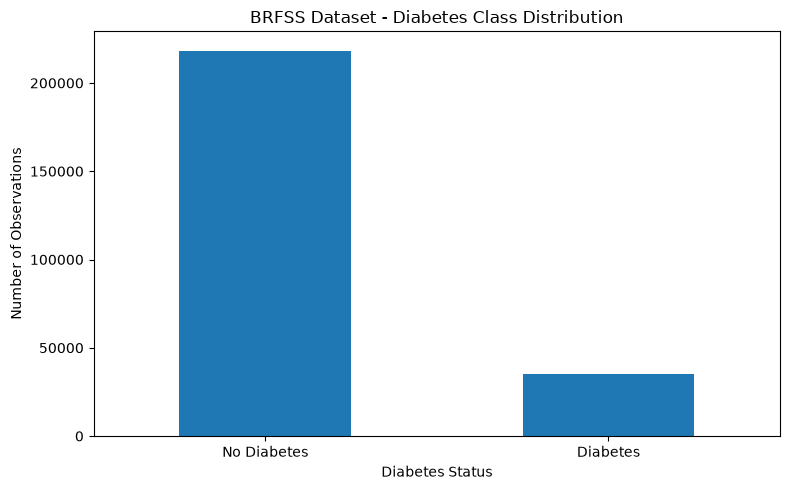

In [46]:
# ============================================================
# Diabetes Class Distribution
# ============================================================

health_class_counts = (
    health_df["Diabetes_binary"]
    .value_counts()
    .sort_index()
)

health_class_counts.index = [
    "No Diabetes",
    "Diabetes"
]

plt.figure(figsize=(8, 5))

health_class_counts.plot(
    kind="bar"
)

plt.title("BRFSS Dataset - Diabetes Class Distribution")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### The target distribution is imbalanced and unequal class sizes can make accuracy misleading, given the non diabetes class substantially outnumbers the diabetes class, the model may achieve high accuracy while still performing poorly at identifying individuals with diabetes, therefore, recall, F1 score and ROC-AUC will be considered.

In [47]:
# ============================================================
# Target and Predictor variables
# ============================================================

health_target = "Diabetes_binary"

health_features = [
    "HighBP",
    "HighChol",
    "BMI",
    "Smoker",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "GenHlth",
    "Age"
]


health_model_df = health_df[
    health_features + [health_target]
].dropna().copy()


X_health = health_model_df[
    health_features
]

y_health = health_model_df[
    health_target
]

print("Selected Predictors:")

for feature in health_features:
    print(feature)

print("~" * 80)
print("Modeling Dataset Shape:")
print(
    health_model_df.shape
)

print("~" * 120)
display(
    X_health.describe().round(2)
)

print("~" * 120)

Selected Predictors:
HighBP
HighChol
BMI
Smoker
HeartDiseaseorAttack
PhysActivity
GenHlth
Age
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Modeling Dataset Shape:
(253680, 9)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


,HighBP,HighChol,BMI,Smoker,HeartDiseaseorAttack,PhysActivity,GenHlth,Age
count,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00
mean,0.43,0.42,28.38,0.44,0.09,0.76,2.51,8.03
std,0.49,0.49,6.61,0.50,0.29,0.43,1.07,3.05
min,0.00,0.00,12.00,0.00,0.00,0.00,1.00,1.00
25%,0.00,0.00,24.00,0.00,0.00,1.00,2.00,6.00
50%,0.00,0.00,27.00,0.00,0.00,1.00,2.00,8.00
75%,1.00,1.00,31.00,1.00,0.00,1.00,3.00,10.00
max,1.00,1.00,98.00,1.00,1.00,1.00,5.00,13.00


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


#### we selected 8 predictors to keep the SVM analysis interpretable while representing several dimensions of health. The predictors include high blood pressure, high cholestral, BMI, smoking, heart disease or heart attack history, physical activity, general health and age. Diabetes_binary is the classification target.

In [48]:
# ============================================================
# Train-Test Split
# ============================================================
# The data is divided into 80% training and 20% testing sets, 
# stratification preserves approximately the same diabetes class distribution in both datasets, as the target variable is imbalanced.

X_health_train, X_health_test, y_health_train, y_health_test = train_test_split(
    X_health,
    y_health,
    test_size=0.20,
    random_state=42,
    stratify=y_health
)


print("Training Data Shape:")
print(
    X_health_train.shape
)

print()

print("Testing Data Shape:")
print(
    X_health_test.shape
)

print()

print("Training Target Percentage:")

display(
    (
        y_health_train
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

print("~" * 80)

Training Data Shape:
(202944, 8)

Testing Data Shape:
(50736, 8)

Training Target Percentage:


Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [49]:
# ============================================================
# Feature Scaling
# ============================================================

health_scaler = StandardScaler()

X_health_train_scaled = health_scaler.fit_transform(
    X_health_train
)

X_health_test_scaled = health_scaler.transform(
    X_health_test
)

health_scaled_df = pd.DataFrame(
    X_health_train_scaled,
    columns=health_features
)

print("Before Standardization:")
display(
    X_health_train.head()
)

print("~" * 80)
print("After Standardization:")
display(
    health_scaled_df.head()
)
print("~" * 80)
print("Mean After Standardization:")

display(
    health_scaled_df.mean().round(3)
)

print("~" * 80)
print("Standard Deviation After Standardization:")

display(
    health_scaled_df.std().round(3)
)

print("~" * 80)

Before Standardization:


,HighBP,HighChol,BMI,Smoker,HeartDiseaseorAttack,PhysActivity,GenHlth,Age
153147,0.0,0.0,28.0,1.0,0.0,1.0,2.0,2.0
176137,1.0,0.0,23.0,1.0,0.0,1.0,2.0,13.0
175578,1.0,1.0,29.0,0.0,0.0,1.0,1.0,9.0
177887,1.0,1.0,39.0,0.0,0.0,0.0,4.0,7.0
182143,0.0,1.0,16.0,1.0,0.0,1.0,5.0,7.0


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
After Standardization:


,HighBP,HighChol,BMI,Smoker,HeartDiseaseorAttack,PhysActivity,GenHlth,Age
0,-0.866775,-0.858504,-0.057282,1.121626,-0.322575,0.566584,-0.479079,-1.977081
1,1.153702,-0.858504,-0.815055,1.121626,-0.322575,0.566584,-0.479079,1.627845
2,1.153702,1.164817,0.094273,-0.891563,-0.322575,0.566584,-1.415079,0.316963
3,1.153702,1.164817,1.609820,-0.891563,-0.322575,-1.764962,1.392923,-0.338479
4,-0.866775,1.164817,-1.875938,1.121626,-0.322575,0.566584,2.328923,-0.338479


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Mean After Standardization:


HighBP                 -0.0
HighChol               -0.0
BMI                     0.0
Smoker                  0.0
HeartDiseaseorAttack   -0.0
PhysActivity            0.0
GenHlth                 0.0
Age                    -0.0
dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Standard Deviation After Standardization:


HighBP                  1.0
HighChol                1.0
BMI                     1.0
Smoker                  1.0
HeartDiseaseorAttack    1.0
PhysActivity            1.0
GenHlth                 1.0
Age                     1.0
dtype: float64

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


SVM Models are sensitive to the scale of predictor variables because the algorithm uses distance and margins when constructing the decision boundary. StandardScaler transforms each predictor so that it is centered approximately around zero with a standard deviation of approximately one.

Scaling Comparison:


,Before Scaling,After Scaling
BMI,28.378,0.718
GenHlth,2.512,0.842
Age,8.033,0.813


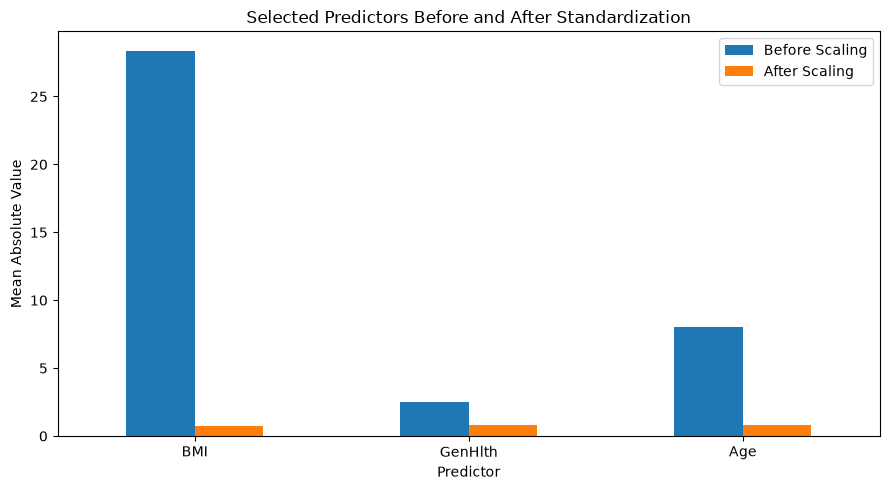

In [50]:
# ============================================================
# Feature Scaling Comparison
# ============================================================

scaling_features = [
    "BMI",
    "GenHlth",
    "Age"
]

before_scaling = (
    X_health_train[
        scaling_features
    ]
    .abs()
    .mean()
)

after_scaling = (
    health_scaled_df[
        scaling_features
    ]
    .abs()
    .mean()
)

scaling_comparison = pd.DataFrame({
    "Before Scaling": before_scaling,
    "After Scaling": after_scaling
})

print("Scaling Comparison:")
display(
    scaling_comparison.round(3)
)


scaling_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)
plt.title("Selected Predictors Before and After Standardization")
plt.xlabel("Predictor")
plt.ylabel("Mean Absolute Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The selected predictors orginally operate on different numerical scales. Standardization places the predictors on comparable scales, preventing variables with larger numerical values from dominating the SVM simply because of their measurement scale.

#### Linear SVM

#### A Linear SVM attempts to identify a hyperplane that seperates the two diabetes classes while maximizing the margin between them, becuase the target class in imbalanced, class_weight="balanced" is used so the minority diabetes class receives greater weight during model fitting.

In [51]:
# ============================================================
# Linear Support Vector Machine
# ============================================================

health_linear_svm = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=10000
)

health_linear_svm.fit(
    X_health_train_scaled,
    y_health_train
)

health_linear_pred = health_linear_svm.predict(
    X_health_test_scaled
)

health_linear_score = health_linear_svm.decision_function(
    X_health_test_scaled
)

print("Linear SVM Model Completed.")
print("~" * 80)

Linear SVM Model Completed.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [52]:
# ============================================================
# Evaluate Linear SVM
# ============================================================

linear_accuracy = accuracy_score(y_health_test, health_linear_pred)
linear_precision = precision_score(y_health_test, health_linear_pred)
linear_recall = recall_score(y_health_test, health_linear_pred)
linear_f1 = f1_score(y_health_test, health_linear_pred)
linear_auc = roc_auc_score(y_health_test, health_linear_score)

print("LINEAR SVM RESULTS")
print("Accuracy:", round(linear_accuracy, 4))
print("Precision:", round(linear_precision, 4))
print("Recall:", round(linear_recall, 4))
print("F1 Score:", round(linear_f1, 4))
print("ROC-AUC:", round(linear_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_health_test, health_linear_pred))

print("\nClassification Report:")
print(classification_report(y_health_test, health_linear_pred, zero_division=0))

LINEAR SVM RESULTS
Accuracy: 0.7224
Precision: 0.3032
Recall: 0.764
F1 Score: 0.4341
ROC-AUC: 0.8138

Confusion Matrix:
[[31252 12415]
 [ 1668  5401]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.95      0.72      0.82     43667
         1.0       0.30      0.76      0.43      7069

    accuracy                           0.72     50736
   macro avg       0.63      0.74      0.63     50736
weighted avg       0.86      0.72      0.76     50736



#### The linear SVM achieved an accuracy of 72.24% and ROC-AUC of 0.8138, indicating good overall ability to distinguish between individuals with and without diabetes. The model achieved a relatively high recall of 76.4% meaning that it correctly identified approximately three fourths of the actual diabetes cases. However the precision was considerably lower at 30.32%, indicating that many individuals predicted as having diabetes were actually non-diaetes. This produced an F1 score of 0.4331. Because the diabetes outcome is imbalanced, the high recall is particularly important and demonstrates why accuracy alone should not be used to evaluate this model. 

#### Overall the Linear SVM favors sensitivity to diabetes cases over precision, identifying a large proportion of actual diabetes cases at the cost of more false-positive classifications.

Linear SVM Coefficients:


,Feature,Coefficient,Absolute_Coefficient
3,Smoker,0.0031,0.0031
5,PhysActivity,-0.0105,0.0105
4,HeartDiseaseorAttack,0.0378,0.0378
1,HighChol,0.1116,0.1116
0,HighBP,0.1608,0.1608
7,Age,0.1769,0.1769
2,BMI,0.1804,0.1804
6,GenHlth,0.2427,0.2427


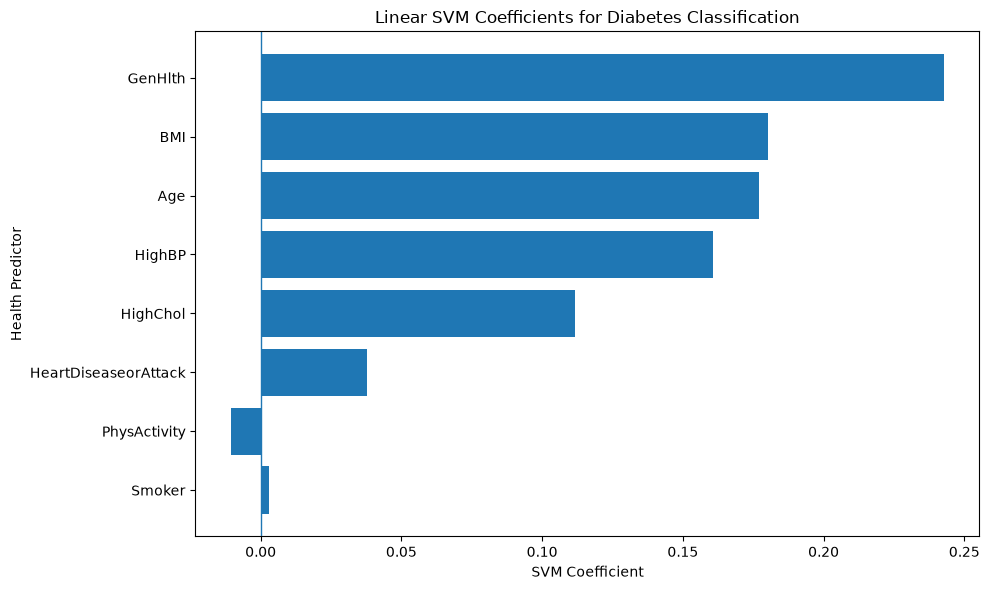

In [53]:
# ============================================================
# Linear SVM Coefficients
# ============================================================

svm_coefficient_df = pd.DataFrame({
    "Feature": health_features,
    "Coefficient": health_linear_svm.coef_[0]
})

svm_coefficient_df["Absolute_Coefficient"] = abs(
    svm_coefficient_df["Coefficient"]
)

svm_coefficient_df = svm_coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=True
)

print("Linear SVM Coefficients:")

display(
    svm_coefficient_df.round(4)
)

plt.figure(figsize=(10, 6))
plt.barh(svm_coefficient_df["Feature"], svm_coefficient_df["Coefficient"])
plt.axvline(x=0, linewidth=1)
plt.xlabel("SVM Coefficient")
plt.ylabel("Health Predictor")
plt.title("Linear SVM Coefficients for Diabetes Classification")
plt.tight_layout()
plt.show()

#### The coefficient graph shows how each standardized predictor contributes to the linear SVM decision function. Predictors with larger absolute coefficients have greater influence on the linear decision boundary. Positive and Negative coefficients contribute in opposite directions to the decision score. These coefficients describe the associations within the fitted classification model and should not be interpreted as causal effects.

### The kernel Trick

#### A linear SVM creates a linear decision boundary, however as we have seen in the previous milestone and previous week homework the relationships between health characteristics and diabetes may not be completely linear. The kernel trick allows SVM to model more complex boundaries without manually creating all possible nonlinear transformations.

#### We will compare three kernels - Linear, Polynomial and RBF, given the dataset is large we will use stratified sample.


In [54]:
# ============================================================
# Creating Stratified Sample for Kernel SVM
# ============================================================

health_kernel_df, unused_health_df = train_test_split(
    health_model_df,
    train_size=15000,
    random_state=42,
    stratify=health_model_df[health_target]
)

X_health_kernel = health_kernel_df[
    health_features
]

y_health_kernel = health_kernel_df[
    health_target
]

X_hk_train, X_hk_test, y_hk_train, y_hk_test = train_test_split(
    X_health_kernel,
    y_health_kernel,
    test_size=0.20,
    random_state=42,
    stratify=y_health_kernel
)

kernel_scaler = StandardScaler()

X_hk_train_scaled = kernel_scaler.fit_transform(
    X_hk_train
)

X_hk_test_scaled = kernel_scaler.transform(
    X_hk_test
)
print("Kernel SVM Sample Shape:")
print(
    health_kernel_df.shape
)
print()
print("Kernel Training Shape:")
print(
    X_hk_train.shape
)
print()
print("Kernel Testing Shape:")
print(
    X_hk_test.shape
)

print("~" * 80)


Kernel SVM Sample Shape:
(15000, 9)

Kernel Training Shape:
(12000, 8)

Kernel Testing Shape:
(3000, 8)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [55]:
# ============================================================
# Linear Kernel SVM
# ============================================================

health_svm_linear = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced"
)


health_svm_linear.fit(
    X_hk_train_scaled,
    y_hk_train
)

health_pred_linear = health_svm_linear.predict(
    X_hk_test_scaled
)

health_score_linear = health_svm_linear.decision_function(
    X_hk_test_scaled
)
print("Linear Kernel Completed.")
print("~" * 80)

Linear Kernel Completed.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [56]:
# ============================================================
# Polynomial Kernel SVM
# ============================================================

health_svm_poly = SVC(
    kernel="poly",
    degree=2,
    C=1.0,
    gamma="scale",
    class_weight="balanced"
)

health_svm_poly.fit(
    X_hk_train_scaled,
    y_hk_train
)

health_pred_poly = health_svm_poly.predict(
    X_hk_test_scaled
)

health_score_poly = health_svm_poly.decision_function(
    X_hk_test_scaled
)

print("Polynomial Kernel Completed.")

print("~" * 80)

Polynomial Kernel Completed.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [57]:
# ============================================================
# RBF Kernel SVM
# ============================================================

health_svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced"
)

health_svm_rbf.fit(
    X_hk_train_scaled,
    y_hk_train
)

health_pred_rbf = health_svm_rbf.predict(
    X_hk_test_scaled
)

health_score_rbf = health_svm_rbf.decision_function(
    X_hk_test_scaled
)

print("RBF Kernel Completed.")
print("~" * 80)

RBF Kernel Completed.
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [58]:
# ============================================================
# Compare SVM Kernels
# ============================================================

health_kernel_results = pd.DataFrame({
    "Kernel": ["Linear", "Polynomial", "RBF"],

    "Accuracy": [
        accuracy_score(y_hk_test, health_pred_linear),
        accuracy_score(y_hk_test, health_pred_poly),
        accuracy_score(y_hk_test, health_pred_rbf)
    ],

    "Precision": [
        precision_score(y_hk_test, health_pred_linear),
        precision_score(y_hk_test, health_pred_poly),
        precision_score(y_hk_test, health_pred_rbf)
    ],

    "Recall": [
        recall_score(y_hk_test, health_pred_linear),
        recall_score(y_hk_test, health_pred_poly),
        recall_score(y_hk_test, health_pred_rbf)
    ],

    "F1_Score": [
        f1_score(y_hk_test, health_pred_linear),
        f1_score(y_hk_test, health_pred_poly),
        f1_score(y_hk_test, health_pred_rbf)
    ],

    "ROC_AUC": [
        roc_auc_score(y_hk_test, health_score_linear),
        roc_auc_score(y_hk_test, health_score_poly),
        roc_auc_score(y_hk_test, health_score_rbf)
    ]
})

display(health_kernel_results.round(4))

,Kernel,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Linear,0.7007,0.2876,0.7775,0.4199,0.8096
1,Polynomial,0.6230,0.2365,0.7656,0.3614,0.7347
2,RBF,0.6920,0.2841,0.7967,0.4189,0.7963


#### The Linear kernel produced the strongest overall performance, with the highest accuracy of 70.07% precision 28.76%, F1 Score of 0.4199 and ROC-AUC 0.8096. The RBK kernel produced a slightly lower accuracy of 69.20% and ROC-AUC of 0.7963 but achieved highest recall of 79.63%. The polynomial kernel performed substantially worse with an accuracy of 62.30% F1 score of 0.3614 and ROC-AUC of 0.7347

#### These results show that applying the kernel trick didn't improve overall predictive performance compared with the Linear Kernel. Although the RBF Kernel increased recall slightly its overall discrimination was lower. This suggests that for the selected predictors, the additional nonlinear complexity provided by the polynomial and RBF kernels offers limited improvement over a linear decision boundary.

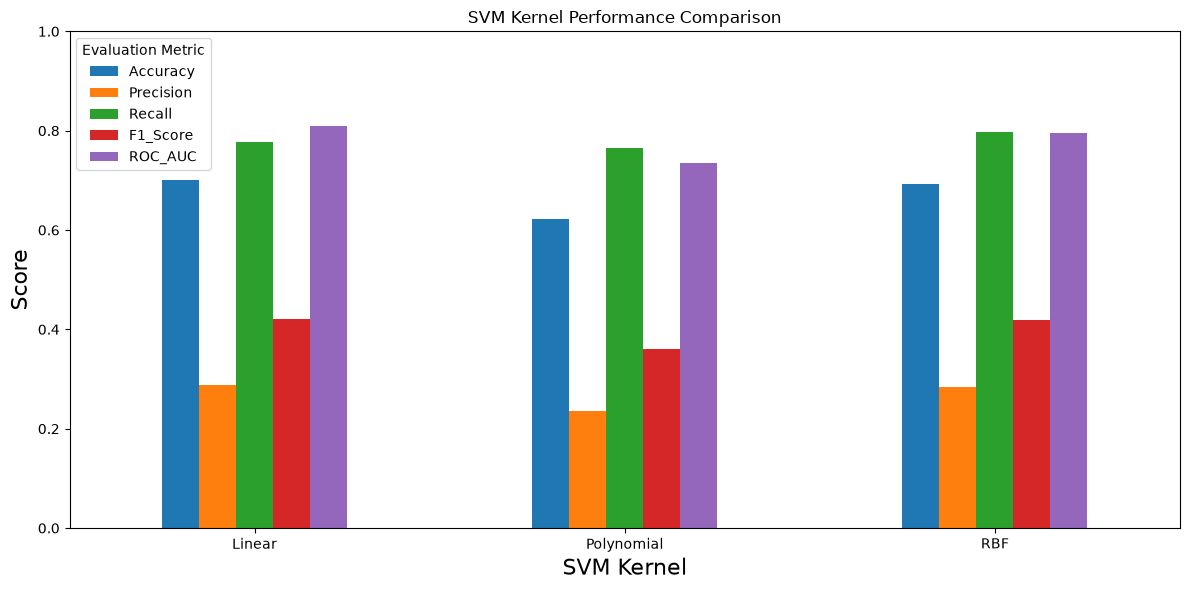

In [64]:
# ============================================================
# Kernel Performance Comparison
# ============================================================

health_kernel_results.set_index(
    "Kernel"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("SVM Kernel Performance Comparison")
plt.xlabel("SVM Kernel", fontsize=16)
plt.ylabel("Score", fontsize=16)
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()


Linear Kernel Confusion Matrix
[[1777  805]
 [  93  325]]


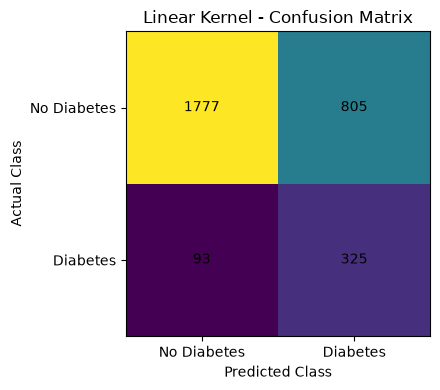


Polynomial Kernel Confusion Matrix
[[1549 1033]
 [  98  320]]


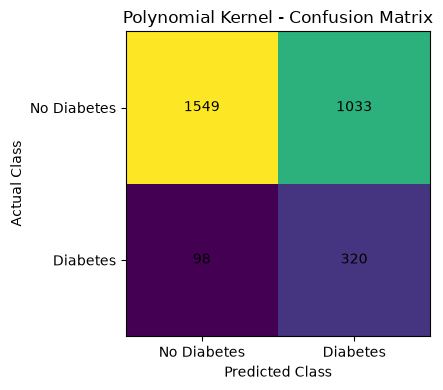


RBF Kernel Confusion Matrix
[[1743  839]
 [  85  333]]


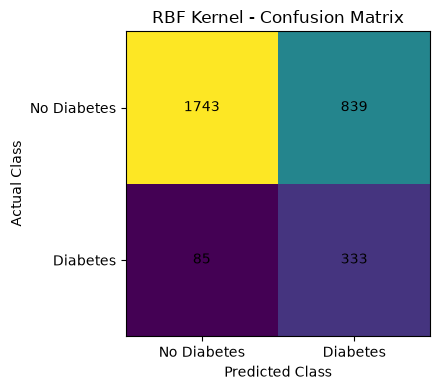

In [60]:
# ============================================================
# Confusion Matrices - SVM Kernels
# ============================================================

kernel_predictions = {
    "Linear": health_pred_linear,
    "Polynomial": health_pred_poly,
    "RBF": health_pred_rbf
}

for kernel, predictions in kernel_predictions.items():

    cm = confusion_matrix(y_hk_test, predictions)

    print(f"\n{kernel} Kernel Confusion Matrix")
    print(cm)

    plt.figure(figsize=(5, 4))
    plt.imshow(cm)

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.title(f"{kernel} Kernel - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
    plt.yticks([0, 1], ["No Diabetes", "Diabetes"])
    plt.tight_layout()
    plt.show()

SVM Regularization Results:


,C,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Support_Vectors
0,0.01,0.6663,0.2707,0.8230,0.4073,0.8080,8157
1,0.10,0.6920,0.2849,0.8014,0.4203,0.8045,6970
2,1.00,0.6920,0.2841,0.7967,0.4189,0.7963,6569
3,10.00,0.6943,0.2825,0.7751,0.4141,0.7804,6354
4,100.00,0.6963,0.2789,0.7440,0.4057,0.7581,6127


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


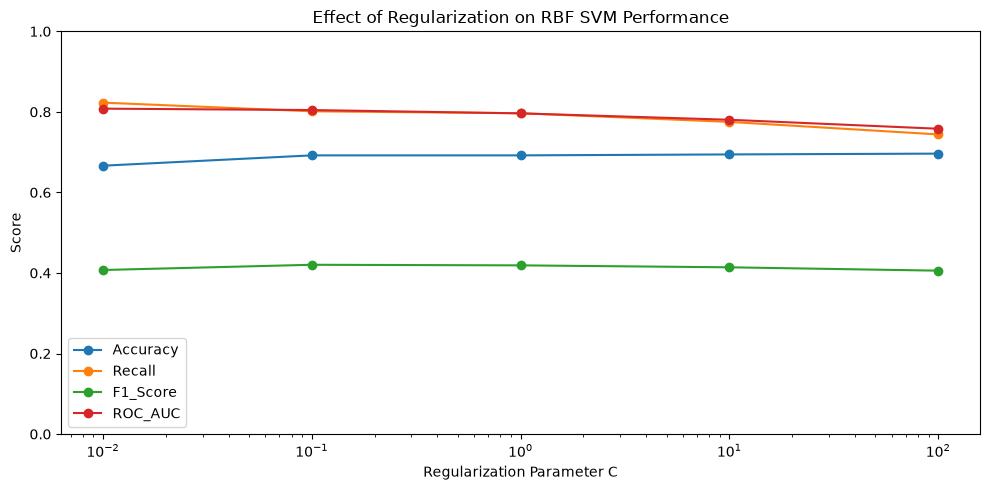

In [61]:
# ============================================================
# SVM Regularization
# ============================================================

C_values = [0.01, 0.1, 1, 10, 100]
regularization_results = []

for C_value in C_values:
    svm_model = SVC(kernel="rbf", C=C_value, gamma="scale", class_weight="balanced")
    svm_model.fit(X_hk_train_scaled, y_hk_train)

    svm_prediction = svm_model.predict(X_hk_test_scaled)
    svm_score = svm_model.decision_function(X_hk_test_scaled)

    regularization_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_hk_test, svm_prediction),
        "Precision": precision_score(y_hk_test, svm_prediction),
        "Recall": recall_score(y_hk_test, svm_prediction),
        "F1_Score": f1_score(y_hk_test, svm_prediction),
        "ROC_AUC": roc_auc_score(y_hk_test, svm_score),
        "Support_Vectors": len(svm_model.support_)
    })

regularization_df = pd.DataFrame(regularization_results)

print("SVM Regularization Results:")
display(regularization_df.round(4))
print("~" * 80)

# ============================================================
# Regularization vs Model Performance
# ============================================================

plt.figure(figsize=(10, 5))

for metric in ["Accuracy", "Recall", "F1_Score", "ROC_AUC"]:
    plt.plot(regularization_df["C"], regularization_df[metric], marker="o", label=metric)

plt.xscale("log")
plt.xlabel("Regularization Parameter C")
plt.ylabel("Score")
plt.title("Effect of Regularization on RBF SVM Performance")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

#### The regularization experiment demonstrates a clear tradeoff between accuracy and the ability to identify diabetes cases. At C= 0.01, the model achieved the highest recall of 82.30% and ROC-AUC(0.8080), but accuracy was lower at 66.63%. Increasing C gradually increased accuracy, raching 69.63% at C=100, but the recall decreased substantially from 82.30% to 74.40%. ROC-AUC also decreased from 0.8080 to 0.7581 as C increased.The highest F1 Score 0.4203 occured at  C = 0.10, suggesting that moderate to strong regularization provided the best balance between precision and recall among the tested RBF models.

In [62]:
# ============================================================
# Best Regularization Result
# ============================================================

best_regularization = regularization_df.loc[[regularization_df["F1_Score"].idxmax()]]

print("BEST REGULARIZATION RESULT")
display(best_regularization.round(4))

BEST REGULARIZATION RESULT


,C,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Support_Vectors
1,0.1,0.692,0.2849,0.8014,0.4203,0.8045,6970


#### Based on F1 score, C=0.10 produced the best regularized RBF SVM. The model achieved 69.2% accuracy, 28.49% precision, 80.14% recall and F1 scopre of 0.4203.

In [63]:
# ============================================================
# Final Results Summary
# ============================================================

linear_summary_df = pd.DataFrame({
    "Model": ["Linear SVM"],
    "Accuracy": [linear_accuracy],
    "Precision": [linear_precision],
    "Recall": [linear_recall],
    "F1_Score": [linear_f1],
    "ROC_AUC": [linear_auc]
})

print("LINEAR SVM - FULL DATASET")
display(linear_summary_df.round(4))

print("KERNEL SVM - STRATIFIED SAMPLE")
display(health_kernel_results.round(4))

print("REGULARIZATION RESULTS")
display(regularization_df.round(4))

LINEAR SVM - FULL DATASET


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Linear SVM,0.7224,0.3032,0.764,0.4341,0.8138


KERNEL SVM - STRATIFIED SAMPLE


,Kernel,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Linear,0.7007,0.2876,0.7775,0.4199,0.8096
1,Polynomial,0.6230,0.2365,0.7656,0.3614,0.7347
2,RBF,0.6920,0.2841,0.7967,0.4189,0.7963


REGULARIZATION RESULTS


,C,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Support_Vectors
0,0.01,0.6663,0.2707,0.8230,0.4073,0.8080,8157
1,0.10,0.6920,0.2849,0.8014,0.4203,0.8045,6970
2,1.00,0.6920,0.2841,0.7967,0.4189,0.7963,6569
3,10.00,0.6943,0.2825,0.7751,0.4141,0.7804,6354
4,100.00,0.6963,0.2789,0.7440,0.4057,0.7581,6127


# Week 5 summary and Impression

This analysis applied Support Vector Machines to the BRFSS diabetes dataset using eight health predictors. Because only 13.93% of observations were in the diabetes class, I evaluated the models using precision, recall, F1, ROC-AUC, and confusion matrices in addition to accuracy. The predictors were standardized using StandardScaler. The full-dataset Linear SVM achieved 72.24% accuracy, 76.40% recall, F1 = 0.4341, and ROC-AUC = 0.8138, correctly identifying 5,401 of 7,069 diabetes cases. The relatively high recall was useful for identifying diabetes cases, although the lower precision (30.32%) showed that this resulted in more false positives.

To test the kernel trick, I compared linear, polynomial, and RBF kernels using the same 15,000-observation stratified sample. The linear kernel performed best overall, with F1 = 0.4199 and ROC-AUC = 0.8096, while the RBF kernel had the highest recall (0.7967). The polynomial kernel performed weakest. This was somewhat unexpected because I expected nonlinear kernels to improve classification, but the additional complexity did not improve overall performance.

I also tested SVM regularization using RBF models with C values from 0.01 to 100. Smaller C values provided stronger regularization and generally better recall, while larger values slightly improved accuracy but reduced recall and ROC-AUC. Based on F1, C = 0.10 provided the best balance with recall = 0.8014, F1 = 0.4203, and ROC-AUC = 0.8045. Stratified train-test splits and training-only feature scaling were used to evaluate generalization and avoid data leakage. Overall, the results showed that more model complexity did not necessarily produce better diabetes classification, and metrics such as recall and F1 were more informative than accuracy alone for this imbalanced dataset.